In [33]:
import pandas as pd
import sys
sys.path.insert(0, ".")
from churn_utils import clean_total_charges, add_churn_flag, add_model_features, add_split

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = clean_total_charges(df)
df = add_churn_flag(df)
df = add_model_features(df)
df = add_split(df)

print(df["TotalCharges"].isna().sum(), df["ChurnFlag"].mean())
print(df["IsMonthToMonth"].sum(), df["IsFiber"].sum(), df["IsElectronicCheck"].sum())
print(df["Split"].value_counts())
print(df.shape)
df.head()



(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [34]:
print(df.shape)

(7043, 21)


In [35]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [36]:
# Ver los valores problemáticos antes de tocarlos
df[df["TotalCharges"].str.strip() == ""][["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [37]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())   # cuántos vacíos quedaron
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isna().sum())   # debe ser 0
df["TotalCharges"].dtype

11
0


dtype('float64')

In [38]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isna().sum())
print(df["TotalCharges"].dtype)

0
0
float64


In [39]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print(df["ChurnFlag"].mean())
print(df.groupby("Contract")["ChurnFlag"].mean())

0.2653698707936959
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: ChurnFlag, dtype: float64


In [40]:
df["IsMonthToMonth"] = (df["Contract"] == "Month-to-month").astype(int)
df["IsFiber"] = (df["InternetService"] == "Fiber optic").astype(int)
df["IsElectronicCheck"] = (df["PaymentMethod"] == "Electronic check").astype(int)
df["tenure_s"] = df["tenure"] / 72
df["MonthlyCharges_s"] = df["MonthlyCharges"] / 120

print(df["IsMonthToMonth"].sum(), df["IsFiber"].sum(), df["IsElectronicCheck"].sum())

3875 3096 2365


In [41]:
df["Split"] = ["Test" if (i + 1) % 5 == 0 else "Train" for i in range(len(df))]
print(df["Split"].value_counts())

Split
Train    5635
Test     1408
Name: count, dtype: int64


In [42]:
from sklearn.linear_model import LogisticRegression
import numpy as np

features = ["tenure_s", "MonthlyCharges_s", "IsMonthToMonth", "IsFiber", "IsElectronicCheck"]

train = df[df["Split"] == "Train"]
test = df[df["Split"] == "Test"]

model = LogisticRegression(C=np.inf, max_iter=1000)
model.fit(train[features], train["ChurnFlag"])

print("Intercept:", model.intercept_[0])
for name, coef in zip(features, model.coef_[0]):
    print(name, coef)

Intercept: -2.5023228994296964
tenure_s -2.4764200711229454
MonthlyCharges_s 1.678723706076621
IsMonthToMonth 1.1306775445148851
IsFiber 0.7803642058190177
IsElectronicCheck 0.5905752447459223


In [43]:
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score, f1_score

proba = model.predict_proba(test[features])[:, 1]
pred = (proba >= 0.30).astype(int)
y = test["ChurnFlag"]

print("AUC:", roc_auc_score(y, proba))
print(confusion_matrix(y, pred))
print("Precision:", precision_score(y, pred))
print("Recall:", recall_score(y, pred))
print("F1:", f1_score(y, pred))

AUC: 0.8182770842965017
[[796 234]
 [ 99 279]]
Precision: 0.543859649122807
Recall: 0.7380952380952381
F1: 0.6262626262626263


In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=20,
    random_state=42,
)
rf.fit(train[features], train["ChurnFlag"])

proba_rf = rf.predict_proba(test[features])[:, 1]
print("AUC Random Forest:", roc_auc_score(y, proba_rf))
print("AUC Logistic Regression:", roc_auc_score(y, proba))

AUC Random Forest: 0.8297195253505932
AUC Logistic Regression: 0.8182770842965017


In [45]:
from sklearn.ensemble import RandomForestClassifier

cat_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
            "PaperlessBilling", "PaymentMethod"]
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

X_all = pd.get_dummies(df[cat_cols + num_cols], columns=cat_cols, dtype=int)
X_train = X_all[df["Split"] == "Train"]
X_test = X_all[df["Split"] == "Test"]

rf_all = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42)
rf_all.fit(X_train, train["ChurnFlag"])

proba_all = rf_all.predict_proba(X_test)[:, 1]
print(X_all.shape)
print("AUC Random Forest (all variables):", roc_auc_score(y, proba_all))

(7043, 45)
AUC Random Forest (all variables): 0.8382917244567729


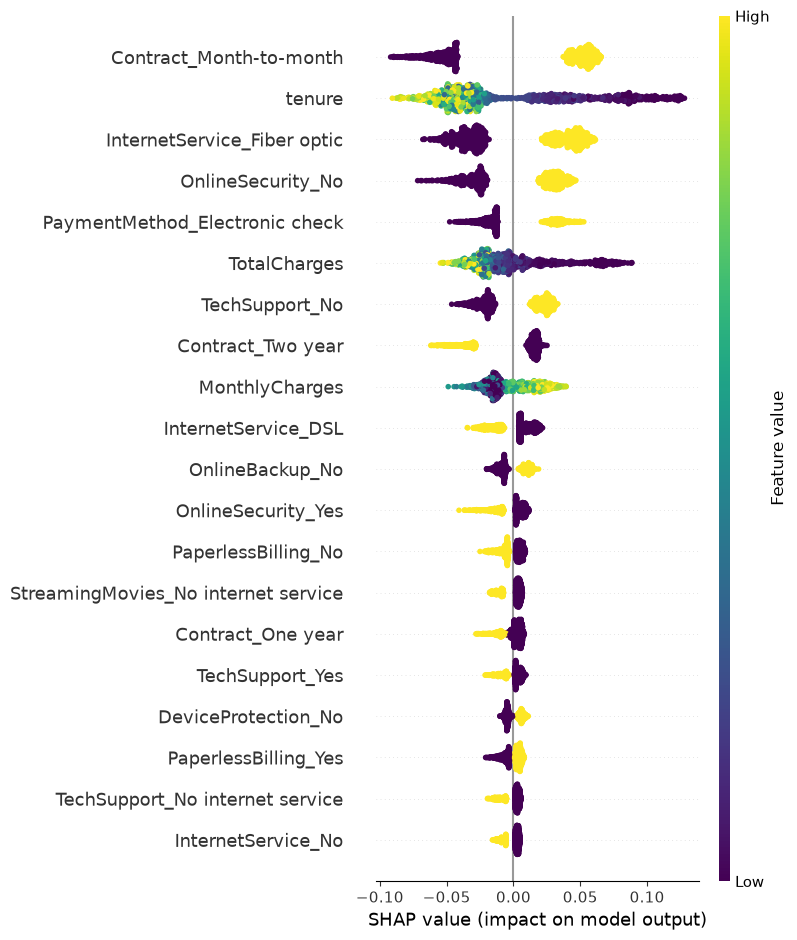

In [48]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(rf_all)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, X_test, cmap="viridis", show=False)
plt.savefig("../docs/images/07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()